<center><h1>Zhan_Jenna_HW6</h1></center>

Name:Jenna Zhan 
<br>
Github Username:jenna-zhan 
<br>
USC ID: 2477604908

## 1. Tree-Based Methods

Import packages

In [1]:
import pandas as pd
from sklearn.impute import SimpleImputer
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score
from sklearn.metrics import roc_curve, roc_auc_score
from xgboost import XGBClassifier
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline

### (a) Download the APS Failure data

In [2]:
aps_training = pd.read_csv(
    "../data/aps_failure_training_set.csv",
    skiprows = 20,
    na_values = "na"
)

aps_test = pd.read_csv(
    "../data/aps_failure_test_set.csv",
    skiprows = 20,
    na_values = "na"
)

print(aps_training.shape)
print(aps_test.shape)

aps_training.head()

(60000, 171)
(16000, 171)


,class,aa_000,ab_000,ac_000,ad_000,ae_000,af_000,ag_000,ag_001,ag_002,...,ee_002,ee_003,ee_004,ee_005,ee_006,ee_007,ee_008,ee_009,ef_000,eg_000
0,neg,76698,NaN,2.130706e+09,280.0,0.0,0.0,0.0,0.0,0.0,...,1240520.0,493384.0,721044.0,469792.0,339156.0,157956.0,73224.0,0.0,0.0,0.0
1,neg,33058,NaN,0.000000e+00,NaN,0.0,0.0,0.0,0.0,0.0,...,421400.0,178064.0,293306.0,245416.0,133654.0,81140.0,97576.0,1500.0,0.0,0.0
2,neg,41040,NaN,2.280000e+02,100.0,0.0,0.0,0.0,0.0,0.0,...,277378.0,159812.0,423992.0,409564.0,320746.0,158022.0,95128.0,514.0,0.0,0.0
3,neg,12,0.0,7.000000e+01,66.0,0.0,10.0,0.0,0.0,0.0,...,240.0,46.0,58.0,44.0,10.0,0.0,0.0,0.0,4.0,32.0
4,neg,60874,NaN,1.368000e+03,458.0,0.0,0.0,0.0,0.0,0.0,...,622012.0,229790.0,405298.0,347188.0,286954.0,311560.0,433954.0,1218.0,0.0,0.0


### (b) Data Preparation

#### (i) Research what types of techniques are usually used

Common techniques for handling missing values include deleting observations
with missing values, mean/median/mode imputation, forward or backward filling,
and interpolation.

For this dataset, I use median imputation because deleting observations may
result in substantial data loss, and median imputation is less sensitive to
extreme values than mean imputation.

Reference:
https://www.geeksforgeeks.org/data-analysis/handling-missing-values-machine-learning/

In [3]:
X_train = aps_training.drop(columns = "class")
y_train = aps_training["class"]

X_test = aps_test.drop(columns = "class")
y_test = aps_test["class"]

In [4]:
imputer = SimpleImputer(strategy = "median")

X_train_imputed = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns = X_train.columns,
    index = X_train.index
)

X_test_imputed = pd.DataFrame(
    imputer.transform(X_test),
    columns = X_test.columns,
    index = X_test.index
)

In [5]:
print(X_train_imputed.isna().sum().sum())
print(X_test_imputed.isna().sum().sum())

0
0


#### (ii) Calculate the coefficient of variation

In [6]:
cv = X_train_imputed.std() / X_train_imputed.mean()

#### (iii) Plot a correlation matrix

In [7]:
corr_matrix = X_train_imputed.corr()

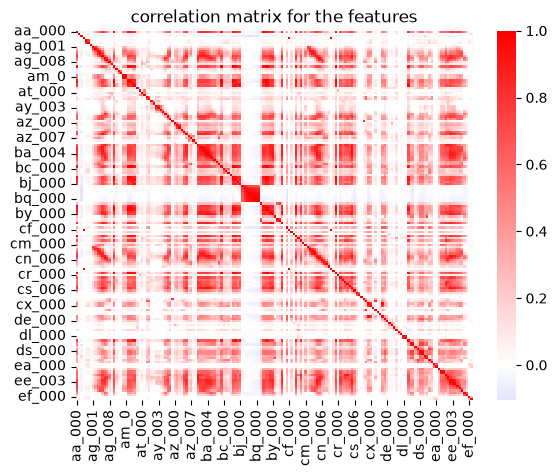

In [8]:
sns.heatmap(
    corr_matrix,
    cmap = "bwr",
    center = 0
)

plt.title("correlation matrix for the features")

plt.show()

#### (iv) Make scatter plots and box plots

In [9]:
n_iv = int(np.floor(np.sqrt(170)))

top_cv_iv = cv.nlargest(n_iv)

top_cv_iv

cf_000    244.887517
co_000    244.507385
ad_000    244.322816
cs_009    237.930554
dh_000    123.216097
dj_000    117.494225
ag_000     92.917755
as_000     87.332500
ay_009     84.733735
ak_000     80.424975
az_009     77.838544
ch_000     77.453857
au_000     68.882751
dtype: float64

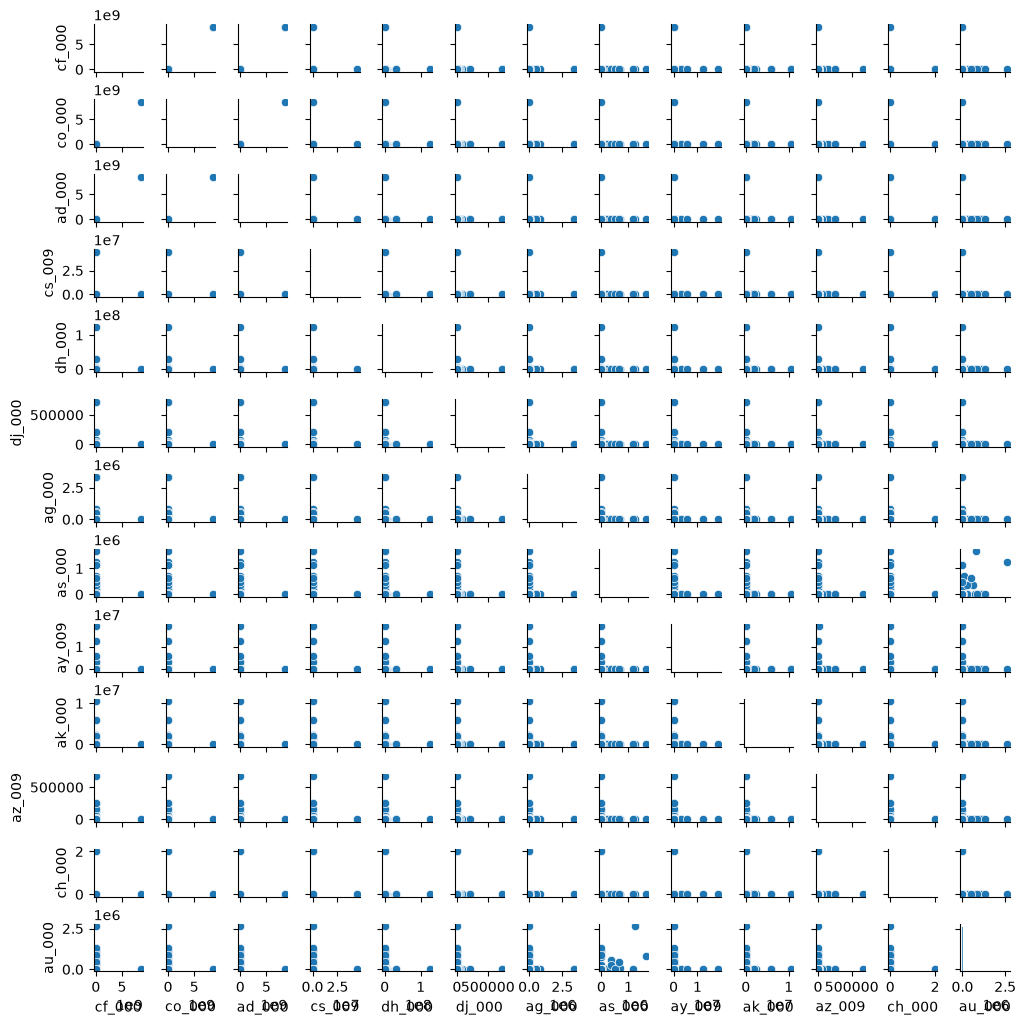

In [10]:
top_features = top_cv_iv.index.tolist()

sns.pairplot(
    X_train_imputed[top_features],
    height=0.8
)

plt.show()

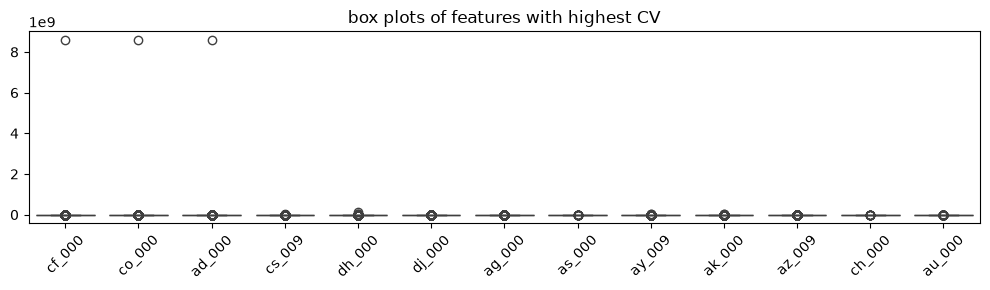

In [11]:
plt.figure(figsize=(10, 3))

sns.boxplot(data = X_train_imputed[top_features])

plt.xticks(rotation = 45)
plt.title("box plots of features with highest CV")
plt.tight_layout()
plt.show()

The scatter plots show that the features are highly skewed, contain extreme values or outliers, and that many observations are concentrated in a relatively small range. Some pairs of features may also appear to be related. However, the scatter plots alone cannot determine whether these features are statistically or predictively significant for class prediction.

#### (v) Is this data set imbalanced?

In [12]:
y_train.value_counts()

class
neg    59000
pos     1000
Name: count, dtype: int64

There are 59,000 negative observations and 1,000 positive observations in the training set. Therefore, the dataset is highly imbalanced, with approximately 98.33% negative observations and 1.67% positive observations.

### (c) Train a random forest

In [13]:
random_f = RandomForestClassifier(
    n_estimators = 500,
    oob_score = True,
    random_state = 552,
    n_jobs = -1
)

random_f.fit(X_train_imputed, y_train);

In [14]:
y_train_pred = random_f.predict(X_train_imputed)
y_test_pred = random_f.predict(X_test_imputed)

cm_train = confusion_matrix(
    y_train,
    y_train_pred,
    labels = ["neg", "pos"]
)

cm_test = confusion_matrix(
    y_test,
    y_test_pred,
    labels = ["neg", "pos"]
)

print("training confusion matrix:")
print(cm_train)

print("test confusion matrix:")
print(cm_test)

training confusion matrix:
[[59000     0]
 [    0  1000]]
test confusion matrix:
[[15606    19]
 [  104   271]]


In [15]:
train_error = 1 - accuracy_score(y_train, y_train_pred)
test_error = 1 - accuracy_score(y_test, y_test_pred)

print("training misclassification error:", train_error)
print("test misclassification error:", test_error)

training misclassification error: 0.0
test misclassification error: 0.007687499999999958


In [16]:
y_train_prob = random_f.predict_proba(X_train_imputed)[:, 1]
y_test_prob = random_f.predict_proba(X_test_imputed)[:, 1]

In [17]:
fpr_train, tpr_train, _ = roc_curve(
    y_train,
    y_train_prob,
    pos_label = "pos"
)

fpr_test, tpr_test, _ = roc_curve(
    y_test,
    y_test_prob,
    pos_label = "pos"
)

auc_train = roc_auc_score(y_train, y_train_prob)
auc_test = roc_auc_score(y_test, y_test_prob)

print("training AUC:", auc_train)
print("test AUC:", auc_test)

training AUC: 1.0
test AUC: 0.9943566506666668


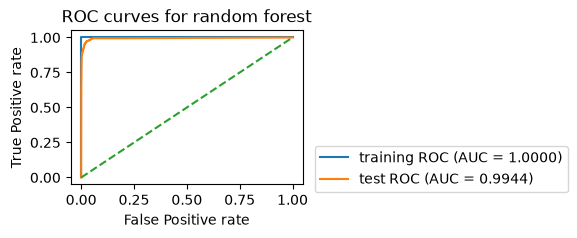

In [18]:
plt.figure(figsize=(3, 2))

plt.plot(
    fpr_train,
    tpr_train,
    label = f"training ROC (AUC = {auc_train:.4f})"
)

plt.plot(
    fpr_test,
    tpr_test,
    label = f"test ROC (AUC = {auc_test:.4f})"
)

plt.plot([0, 1], [0, 1], "--")

plt.xlabel("False Positive rate")
plt.ylabel("True Positive rate")
plt.title("ROC curves for random forest")
plt.legend(loc="center left",
    bbox_to_anchor=(1.02, 0.1))
plt.show()

In [19]:
oob_error = 1 - random_f.oob_score_

print("OOB error:", oob_error)
print("test error:", test_error)

OOB error: 0.005816666666666692
test error: 0.007687499999999958


The OOB error is 0.5817, while the test error is 0.7688. The OOB error is slightly lower than the test error, but the two are quite close, indicating that the OOB error provides a reasonable estimate of the test error.

### (d) Research class imbalance in random forest

Class imbalance in random forests can be addressed using techniques such as oversampling the minority class, undersampling the majority class, and assigning different weights to the classes. In this problem, I use class weighting to give more importance to the minority class during training.

Reference: https://www.geeksforgeeks.org/machine-learning/bagging-and-random-forest-for-imbalanced-classification/

In [20]:
random_f_ba = RandomForestClassifier(
    n_estimators = 500,
    class_weight = "balanced",
    oob_score = True,
    random_state = 552,
    n_jobs = -1
)

random_f_ba.fit(X_train_imputed, y_train);

/opt/anaconda3/lib/python3.14/site-packages/sklearn/ensemble/_forest.py:589: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(


In [21]:
y_train_pred_ba = random_f_ba.predict(X_train_imputed)
y_test_pred_ba = random_f_ba.predict(X_test_imputed)

In [ ]:
cm_train_ba = confusion_matrix(
    y_train,
    y_train_pred_ba,
    labels = ["neg", "pos"]
)

cm_test_ba = confusion_matrix(
    y_test,
    y_test_pred_ba,
    labels = ["neg", "pos"]
)

print("training confusion matrix:")
print(cm_train_ba)

print("test confusion matrix:")
print(cm_test_ba)

In [ ]:
train_error_ba = 1 - accuracy_score(y_train, y_train_pred_ba)
test_error_ba = 1 - accuracy_score(y_test, y_test_pred_ba)

print("training misclassification error:", train_error_ba)
print("test misclassification error:", test_error_ba)

In [ ]:
y_train_prob_ba = random_f_ba.predict_proba(X_train_imputed)[:, 1]
y_test_prob_ba = random_f_ba.predict_proba(X_test_imputed)[:, 1]

fpr_train_ba, tpr_train_ba, _ = roc_curve(
    y_train,
    y_train_prob_ba,
    pos_label = "pos"
)

fpr_test_ba, tpr_test_ba, _ = roc_curve(
    y_test,
    y_test_prob_ba,
    pos_label = "pos"
)

auc_train_ba = roc_auc_score(y_train, y_train_prob_ba)
auc_test_ba = roc_auc_score(y_test, y_test_prob_ba)

print("training AUC:", auc_train_ba)
print("test AUC:", auc_test_ba)

In [ ]:
plt.figure(figsize=(3, 2))

plt.plot(
    fpr_train_ba,
    tpr_train_ba,
    label=f"training ROC (AUC = {auc_train_ba:.4f})"
)

plt.plot(
    fpr_test_ba,
    tpr_test_ba,
    label=f"test ROC (AUC = {auc_test_ba:.4f})"
)

plt.plot([0, 1], [0, 1], "--")

plt.xlabel("False Positive rate")
plt.ylabel("True Positive rate")
plt.title("ROC curves for balanced random forest")
plt.legend(loc="center left",
    bbox_to_anchor=(1.02, 0.1))
plt.show()

In [ ]:
oob_error_ba = 1 - random_f_ba.oob_score_

print("OOB error:", oob_error_ba)
print("test error:", test_error_ba)

After compensating for class imbalance, the test error increased from 0.7688% to 0.9438%, while the test AUC changed only slightly from 0.9944 to 0.9942. The number of false positives increased from 19 to 53, while the number of false negatives decreased from 104 to 98 and the number of true positives increased from 271 to 277. This indicates that the balanced random forest slightly improved the detection of the minority positive class, but at the cost of more false positives and a higher overall test error. In addition, the OOB error increased from 0.5817% to 1.995%. Overall, class weighting slightly improved the detection of the minority class, but it did not improve the overall classification performance.

### (e) XGBoost and Model Trees

I chose 5-fold cross-validation to estimate the error of the trained model.

In [ ]:
y_train_xgb = y_train.map({"neg": 0, "pos": 1})
y_test_xgb = y_test.map({"neg": 0, "pos": 1})

alpha_values = [0, 0.01, 0.1, 1, 10]
xgb = XGBClassifier(
    objective = "binary:logistic",
    eval_metric = "logloss",
    random_state = 552,
    n_jobs = -1
)

cv = StratifiedKFold(
    n_splits = 5,
    shuffle = True,
    random_state = 552
)

In [ ]:
grid_search = GridSearchCV(
    estimator = xgb,
    param_grid = {"reg_alpha": alpha_values},
    scoring = "accuracy",
    cv = cv,
    n_jobs = -1
)

grid_search.fit(X_train_imputed, y_train_xgb;

In [ ]:
print("best alpha:", grid_search.best_params_["reg_alpha"])
print("best CV accuracy:", grid_search.best_score_)
print("best CV error:", 1 - grid_search.best_score_)

In [ ]:
xgb_best = grid_search.best_estimator_

y_train_pred_xgb = xgb_best.predict(X_train_imputed)
y_test_pred_xgb = xgb_best.predict(X_test_imputed)

train_error_xgb = 1 - accuracy_score(
    y_train_xgb,
    y_train_pred_xgb
)

test_error_xgb = 1 - accuracy_score(
    y_test_xgb,
    y_test_pred_xgb
)

print("training error:", train_error_xgb)
print("5-fold CV error:", 1 - grid_search.best_score_)
print("test error:", test_error_xgb)

The 5-fold cross-validation error is 0.635%, while the test error is 0.63125%. The two errors are very close, indicating that the 5-fold cross-validation error provides a good estimate of the test error.

In [ ]:
cm_train_xgb = confusion_matrix(
    y_train_xgb,
    y_train_pred_xgb,
    labels = [0, 1]
)

cm_test_xgb = confusion_matrix(
    y_test_xgb,
    y_test_pred_xgb,
    labels = [0, 1]
)

print("training confusion matrix:")
print(cm_train_xgb)

print("test confusion matrix:")
print(cm_test_xgb)

In [ ]:
y_train_prob_xgb = xgb_best.predict_proba(X_train_imputed)[:, 1]
y_test_prob_xgb = xgb_best.predict_proba(X_test_imputed)[:, 1]

fpr_train_xgb, tpr_train_xgb, _ = roc_curve(
    y_train_xgb,
    y_train_prob_xgb
)

fpr_test_xgb, tpr_test_xgb, _ = roc_curve(
    y_test_xgb,
    y_test_prob_xgb
)

auc_train_xgb = roc_auc_score(
    y_train_xgb,
    y_train_prob_xgb
)

auc_test_xgb = roc_auc_score(
    y_test_xgb,
    y_test_prob_xgb
)

print("training AUC:", auc_train_xgb)
print("test AUC:", auc_test_xgb)

In [ ]:
plt.figure(figsize=(3, 2))

plt.plot(
    fpr_train_xgb,
    tpr_train_xgb,
    label = f"Training ROC (AUC = {auc_train_xgb:.4f})"
)

plt.plot(
    fpr_test_xgb,
    tpr_test_xgb,
    label = f"Test ROC (AUC = {auc_test_xgb:.4f})"
)

plt.plot([0, 1], [0, 1], "--")

plt.xlabel("False Positive rate")
plt.ylabel("True Positive rate")
plt.title("ROC curves for XGBoost")
plt.legend(loc="center left",
    bbox_to_anchor=(1.02, 0.1))
plt.show()

### (f) Use SMOTE to pre-process your data

In [ ]:
smote = SMOTE(random_state = 552)

xgb_smote = XGBClassifier(
    objective = "binary:logistic",
    eval_metric = "logloss",
    random_state = 552,
    n_jobs = -1
)

pipeline_smote = Pipeline([
    ("smote", smote),
    ("xgb", xgb_smote)
])

In [ ]:
alpha_values = [0, 0.01, 0.1, 1, 10]

grid_search_smote = GridSearchCV(
    estimator = pipeline_smote,
    param_grid = {"xgb__reg_alpha": alpha_values},
    scoring = "accuracy",
    cv = cv,
    n_jobs = -1
)

grid_search_smote.fit(X_train_imputed, y_train_xgb);

print("best alpha:",grid_search_smote.best_params_["xgb__reg_alpha"])
print("best CV accuracy:",grid_search_smote.best_score_)
print("best CV error:",1 - grid_search_smote.best_score_)

In [ ]:
xgb_smote_best = grid_search_smote.best_estimator_

y_train_pred_smote = xgb_smote_best.predict(X_train_imputed)
y_test_pred_smote = xgb_smote_best.predict(X_test_imputed)

train_error_smote = 1 - accuracy_score(
    y_train_xgb,
    y_train_pred_smote
)

test_error_smote = 1 - accuracy_score(
    y_test_xgb,
    y_test_pred_smote
)

print("training error:", train_error_smote)
print("5-fold CV error:", 1 - grid_search_smote.best_score_)
print("test error:", test_error_smote)

The 5-fold cross-validation error is 0.6633%, while the test error is 0.7000%. The two errors are close, indicating that the cross-validation error provides a reasonable estimate of the test error.

In [ ]:
cm_train_smote = confusion_matrix(
    y_train_xgb,
    y_train_pred_smote,
    labels = [0, 1]
)

cm_test_smote = confusion_matrix(
    y_test_xgb,
    y_test_pred_smote,
    labels = [0, 1]
)

print("training confusion matrix:")
print(cm_train_smote)

print("test confusion matrix:")
print(cm_test_smote)

In [ ]:
y_train_prob_smote = xgb_smote_best.predict_proba(X_train_imputed)[:, 1]
y_test_prob_smote = xgb_smote_best.predict_proba(X_test_imputed)[:, 1]

fpr_train_smote, tpr_train_smote, _ = roc_curve(
    y_train_xgb,
    y_train_prob_smote
)

fpr_test_smote, tpr_test_smote, _ = roc_curve(
    y_test_xgb,
    y_test_prob_smote
)

auc_train_smote = roc_auc_score(
    y_train_xgb,
    y_train_prob_smote
)

auc_test_smote = roc_auc_score(
    y_test_xgb,
    y_test_prob_smote
)

print("training AUC:", auc_train_smote)
print("test AUC:", auc_test_smote)

In [ ]:
plt.figure(figsize=(3, 2))

plt.plot(
    fpr_train_smote,
    tpr_train_smote,
    label = f"Training ROC (AUC = {auc_train_smote:.4f})"
)

plt.plot(
    fpr_test_smote,
    tpr_test_smote,
    label = f"Test ROC (AUC = {auc_test_smote:.4f})"
)

plt.plot([0, 1], [0, 1], "--")

plt.xlabel("False Positive rate")
plt.ylabel("True Positive rate")
plt.title("ROC curves for XGBoost with SMOTE")
plt.legend(loc="center left",
    bbox_to_anchor=(1.02, 0.1))
plt.show()

After applying SMOTE, the test error increased slightly from 0.63125% to 0.7000%, while the test AUC increased from 0.9935 to 0.9948. The number of false negatives decreased from 85 to 60, and the number of true positives increased from 290 to 315, indicating improved detection of the minority positive class. However, the number of false positives increased from 16 to 52. The 5-fold cross-validation error also increased slightly from 0.6350% to 0.6633%. Overall, SMOTE improved the detection of the minority class and slightly increased the test AUC, but at the cost of more false positives and a slightly higher overall test error.

## 2. ISLR 6.6.3

#### (a) As we increase s from 0, the training RSS will:

iv. Steadily decrease.

When s = 0, the training RSS is relatively large because all slope coefficients are constrained to zero, so the model cannot use any of the predictors X, so its ability to fit the data is the weakest. As s increases, the allowable range of the coefficients becomes larger, so the training RSS decreases. 

#### (b) Repeat (a) for test RSS.

ii. Decrease initially, and then eventually start increasing in a U shape.

When s is small, the model is too simple and may underfit the data, so the test RSS is relatively large. As s increases, the constraint becomes less restrictive, allowing the model to better capture the relationship between X and Y, so the test RSS decreases. However, when s becomes too large, the model becomes more flexible and may start fitting the noise in the training data, resulting in overfitting and an increase in the test RSS. Therefore, the test RSS initially decreases and then increases, forming a U shape.

#### (c) Repeat (a) for variance.

iii. Steadily increase.

When s is small, the coefficients are strongly constrained, so the model is relatively simple and stable. Therefore, even if the training data changes, the fitted models will be similar, resulting in low variance. As s increases, the constraint on the coefficients becomes weaker and the flexibility of the model increases. The model becomes more sensitive to changes in the training data, so the variance increases. Therefore, the variance steadily increases as s increases.

#### (d) Repeat (a) for (squared) bias.

iv. Steadily decrease.

When s is small, the coefficients are strongly constrained, so the model is simple and tends to underfit, resulting in high squared bias. As s increases, the constraint on the coefficients becomes weaker and the flexibility of the model increases. Therefore, the model can better capture the true relationship between X and Y, so the squared bias gradually decreases. Thus, the squared bias steadily decreases as s increases.

#### (e) Repeat (a) for the irreducible error.

v. Remain constant.

The irreducible error is the error that cannot be eliminated no matter how the model is adjusted. It comes from random noise that cannot be explained by the model. Therefore, the irreducible error remains constant as s changes.

## 3. ISLR 6.6.5

### (a) Write out the ridge regression optimization problem in this setting.

The general ridge regression optimization problem is

$$
\min_{\beta_0,\beta_1,\ldots,\beta_p}
\left\{
\sum_{i=1}^{n}
\left(
y_i-\beta_0-\sum_{j=1}^{p}\beta_jx_{ij}
\right)^2
+
\lambda\sum_{j=1}^{p}\beta_j^2
\right\}.
$$

Since $n=2$, $p=2$, and $\beta_0=0$, the optimization problem becomes

$$
\min_{\beta_1,\beta_2}
\left\{
(y_1-\beta_1x_{11}-\beta_2x_{12})^2
+
(y_2-\beta_1x_{21}-\beta_2x_{22})^2
+
\lambda(\beta_1^2+\beta_2^2)
\right\}.
$$

Using $x_{11}=x_{12}$ and $x_{21}=x_{22}$, this can be simplified to

$$
\min_{\beta_1,\beta_2}
\left\{
(y_1-x_{11}(\beta_1+\beta_2))^2
+
(y_2-x_{21}(\beta_1+\beta_2))^2
+
\lambda(\beta_1^2+\beta_2^2)
\right\}.
$$

### (b) Argue that in this setting, the ridge coefficient estimates satisfy $\hat{\beta}_1 = \hat{\beta}_2$.

From the expression in part (a), we can see that as long as $\beta_1+\beta_2$ remains unchanged, the RSS remains unchanged. Ridge regression also has the penalty term

$$
\lambda(\beta_1^2+\beta_2^2).
$$

When $\beta_1+\beta_2$ is fixed, $\beta_1^2+\beta_2^2$ is minimized when $\beta_1=\beta_2$. Therefore, the RSS remains unchanged while the ridge penalty is minimized. Thus,

$$
\hat{\beta}_1=\hat{\beta}_2.
$$

### (c) Write out the lasso optimization problem in this setting.

The general lasso optimization problem is

$$
\min_{\beta_0,\beta_1,\ldots,\beta_p}
\left\{
\sum_{i=1}^{n}
\left(
y_i-\beta_0-\sum_{j=1}^{p}\beta_jx_{ij}
\right)^2
+
\lambda\sum_{j=1}^{p}|\beta_j|
\right\}.
$$

Since $n=2$, $p=2$, and $\beta_0=0$, the optimization problem becomes

$$
\min_{\beta_1,\beta_2}
\left\{
(y_1-\beta_1x_{11}-\beta_2x_{12})^2
+
(y_2-\beta_1x_{21}-\beta_2x_{22})^2
+
\lambda(|\beta_1|+|\beta_2|)
\right\}.
$$

Using $x_{11}=x_{12}$ and $x_{21}=x_{22}$, this can be simplified to

$$
\min_{\beta_1,\beta_2}
\left\{
(y_1-x_{11}(\beta_1+\beta_2))^2
+
(y_2-x_{21}(\beta_1+\beta_2))^2
+
\lambda(|\beta_1|+|\beta_2|)
\right\}.
$$

### (d) Argue that in this setting, the lasso coefficients $\hat{\beta}_1 and \hat{\beta}_2$ are not unique—in other words, there are many possible solutions to the optimization problem in (c). Describe these solutions.

From part (c), the RSS depends only on $\beta_1+\beta_2$. Suppose that

$$
\beta_1+\beta_2=c,
$$

where $c$ is a constant. Therefore, if $\beta_1+\beta_2=c$ is fixed, the RSS remains unchanged.

For the lasso, the penalty is

$$
\lambda(|\beta_1|+|\beta_2|).
$$

If $\beta_1$ and $\beta_2$ have the same sign as $c$, then

$$
|\beta_1|+|\beta_2|=|\beta_1+\beta_2|=|c|.
$$

Therefore, both the RSS and the lasso penalty remain unchanged for many different combinations of $\beta_1$ and $\beta_2$. Thus, the lasso coefficient estimates are not unique. Any pair satisfying

$$
\beta_1+\beta_2=c
$$

with $\beta_1$ and $\beta_2$ having the same sign as $c$ gives the same objective value.

## 4. ISLR 8.4.5

For the majority vote approach, using 0.5 as the cutoff, a probability less than 0.5 is classified as Green, while a probability greater than 0.5 is classified as Red. There are 4 votes for Green and 6 votes for Red. Therefore, the final classification using majority vote is Red.

For the average probability approach, the average of the ten probabilities is 0.45. Since 0.45 < 0.5, the final classification is Green.

## 5. ISLR 9.7.3

### (a) Sketch the observations.

In [ ]:
red_x1 = [3, 2, 4, 1]
red_x2 = [4, 2, 4, 4]

blue_x1 = [2, 4, 4]
blue_x2 = [1, 3, 1]

plt.figure(figsize=(3, 2))
plt.scatter(red_x1, red_x2, color = "red", label = "Red")
plt.scatter(blue_x1, blue_x2, color = "blue", label = "Blue")

plt.xlabel("X1")
plt.ylabel("X2")
plt.legend(loc="center left",
    bbox_to_anchor=(1.02, 0.1))
plt.grid()

plt.show()

### (b) Sketch the optimal separating hyperplane, and provide the equation for this hyperplane (of the form (9.1)).

In [ ]:

plt.figure(figsize=(3, 2))

plt.scatter(red_x1, red_x2, color = "red", label = "Red")
plt.scatter(blue_x1, blue_x2, color = "blue", label = "Blue")

plt.xlabel("X1")
plt.ylabel("X2")
plt.legend(loc="center left",
    bbox_to_anchor=(1.02, 0.1))
plt.grid()

x = np.linspace(0.5, 4.5, 100)
y = x - 0.5

plt.plot(x, y, color="black", label="Optimal separating hyperplane")

The optimal separating hyperplane is

$$
-0.5 + X_1 - X_2 = 0.
$$

Equivalently,

$$
X_2 = X_1 - 0.5.
$$

### (c) Describe the classification rule for the maximal margin classifier.

The classification rule is

$$
0.5-X_1+X_2>0
$$

for **Red**, and **Blue** otherwise.

Therefore,

$$
\beta_0=0.5,\qquad \beta_1=-1,\qquad \beta_2=1.
$$

### (d) On your sketch, indicate the margin for the maximal margin hyperplane.

In [ ]:
plt.figure(figsize=(3, 2))

plt.scatter(red_x1, red_x2, color = "red", label = "Red")
plt.scatter(blue_x1, blue_x2, color = "blue", label = "Blue")

plt.xlabel("X1")
plt.ylabel("X2")

plt.grid()

x = np.linspace(0.5, 4.5, 100)

plt.plot(
    x, x - 0.5,
    color = "black",
    label = "optimal separating hyperplane"
)

plt.plot(
    x, x,
    color = "gray",
    linestyle = "--",
    label = "Margin"
)

plt.plot(
    x, x - 1,
    color = "gray",
    linestyle = "--"
)

plt.legend(loc="center left",
    bbox_to_anchor=(1.02, 0.1))

### (e) Indicate the support vectors for the maximal margin classifier.

The support vectors are observations 2, 5, and 6, corresponding to the points (2,2), (2,1), and (4,3), respectively.

### (f) Argue that a slight movement of the seventh observation would not affect the maximal margin hyperplane.

Observation 7 is not a support vector and is relatively far from the maximal margin hyperplane. The hyperplane is determined by the support vectors, which are observations 2, 5, and 6. Therefore, a slight movement of observation 7 would not affect the maximal margin hyperplane.

### (g) Sketch a hyperplane that is not the optimal separating hyperplane, and provide the equation for this hyperplane.

In [ ]:
plt.figure(figsize=(3, 2))

plt.scatter(red_x1, red_x2, color = "red", label = "Red")
plt.scatter(blue_x1, blue_x2, color = "blue", label = "Blue")

plt.xlabel("X1")
plt.ylabel("X2")

plt.grid()

plt.plot(
    x,
    x - 0.25,
    linestyle="--",
    label="non-optimal separating hyperplane"
)

plt.legend(loc="center left",
    bbox_to_anchor=(1.02, 0.1))

One possible non-optimal separating hyperplane is

$$
X_2=X_1-0.25,
$$

or equivalently,

$$
0.25-X_1+X_2=0.
$$

This hyperplane still separates the Red and Blue observations, but it does not maximize the margin.

### (h) Draw an additional observation on the plot so that the two classes are no longer separable by a hyperplane.

In [ ]:
plt.figure(figsize=(3, 2))

plt.scatter(red_x1, red_x2, color = "red", label = "Red")
plt.scatter(blue_x1, blue_x2, color = "blue", label = "Blue")

plt.xlabel("X1")
plt.ylabel("X2")

plt.grid()

plt.scatter(
    3, 3.5,
    color = "blue",
    marker = "x",
    s = 100,
    label = "additional Blue observation"
)

plt.legend(loc="center left",
    bbox_to_anchor=(1.02, 0.1)
)
plt.show()